[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/MFM/blob/main/Quantlets/Ch_07/MFM_ch7_precision/MFM_ch7_precision.ipynb)

# MFM_ch7_precision

Precision of historical Value-at-Risk (VaR) 1% and Expected Shortfall (ES) 2.5% for the S&P 500 (2000-2026 and the last 500 days): 95% intervals from i.i.d. and Heteroskedasticity and Autocorrelation Consistent (HAC) asymptotics (Chen, 2008) and from i.i.d. and moving-block bootstraps.

*Modelling Financial Markets (MFM), Chapter 7: Value-at-Risk and Expected Shortfall. Author: Daniel Traian Pele.*

> **Working in Google Colab? Save your own copy first.**
> The Colab link opens a temporary copy: when you close the tab or the session times out, your changes are lost.
> Use **File → Save a copy in Drive** (it goes to the *Colab Notebooks* folder of your ASE Google Drive) and work in that copy.
> For the team project, **File → Save a copy in GitHub** puts the notebook directly in your team's repository.
> Files you create while the notebook runs (CSV, charts) are also temporary: set `SAVE_TO_DRIVE = True` in the next cell to keep them.

In [1]:
# Optional (Colab only): keep the files you create in Google Drive
SAVE_TO_DRIVE = False   # set to True, run this cell and allow access to your Drive

import os
OUT_DIR = '.'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/MFM/Chapter_7'
    os.makedirs(OUT_DIR, exist_ok=True)
    os.chdir(OUT_DIR)  # relative chart and CSV outputs persist in Drive
print('Save your outputs to:', os.path.abspath(OUT_DIR))


Save your outputs to: /private/tmp/claude-501/-Users-danpele-Documents-Teaching/af03725b-c702-4afe-9dc4-afe44f4c7210/scratchpad/nbrun6/Quantlets/Ch_07/MFM_ch7_precision


In [2]:
# Colab: !pip install arch
import os
import re
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, integrate, signal
try:
    from arch import arch_model
except ModuleNotFoundError as exc:
    if exc.name != 'arch':
        raise
    import subprocess
    import sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', 'arch'], check=True)
    from arch import arch_model
import warnings
warnings.filterwarnings('ignore')

## Style and helpers

In [3]:
# Chart style: transparent background, legend below the plot
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['savefig.facecolor'] = 'none'
plt.rcParams['savefig.transparent'] = True
plt.rcParams['axes.grid'] = False
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 9
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.linewidth'] = 0.6
plt.rcParams['lines.linewidth'] = 1.1
plt.rcParams['legend.facecolor'] = 'none'
plt.rcParams['legend.framealpha'] = 0
plt.rcParams['legend.fontsize'] = 8

# Brand colours
MainBlue = '#1A3A6E'
IDAred   = '#CD0000'
Forest   = '#2E7D32'
Amber    = '#B5853F'
Orange   = '#E67E22'
Purple   = '#8E44AD'
Crimson  = '#DC3545'
Navy     = '#1F2A44'   # reference lines (no grey in charts)
BandBlue = '#C5D2E8'   # light MainBlue tint for confidence / reference bands
Gray, LightGray = Navy, BandBlue   # legacy names kept for importing scripts
Teal     = '#17A2B8'
METHOD_COL = {'HS': MainBlue, 'Normal': Orange, 'Student-t': Forest, 'Cornish-Fisher': Purple, 'EVT (GPD)': IDAred}

def _reviewed_layout(fig,name):
    targets={'ch7_caviar','ch7_basel','ch7_precision','ch7_crk_table6','ch7_sem_b4_clusters'}
    if name not in targets:return False
    fig.set_size_inches(5.67,2.65)
    handles=[];labels=[]
    for ax in fig.axes:
        h,l=ax.get_legend_handles_labels()
        for hi,li in zip(h,l):
            if li not in labels:handles.append(hi);labels.append(li)
        ax.tick_params(labelsize=8)
        ax.xaxis.label.set_fontsize(9);ax.yaxis.label.set_fontsize(9)
        ax.title.set_fontsize(10)
        for t in ax.texts:t.set_fontsize(8)
        if ax.get_legend():ax.get_legend().remove()
    for leg in list(fig.legends):leg.remove()
    ax=fig.axes[0];ncol=2;legsize=8
    if name=='ch7_caviar':
        for line in ax.lines:
            if line.get_label().startswith('CAViaR'):line.set_zorder(5);line.set_linestyle('--');line.set_linewidth(1.2)
            elif line.get_label().startswith('FHS'):line.set_alpha(.65);line.set_linewidth(.8)
        ax.set_title('S&P 500: out-of-sample VaR 1%, 2016–2026',fontsize=10)
        labels=[('Daily loss (positive part)' if x.startswith('Daily loss') else 'CAViaR: fit 2000–2015' if x.startswith('CAViaR') else 'FHS: refit each January') for x in labels];ncol=3;legsize=7.5
        fig.subplots_adjust(left=.10,right=.99,top=.84,bottom=.25)
    elif name=='ch7_basel':
        ax.set_title('Historical simulation: ES/VaR ratios above bars',fontsize=10)
        ax.set_ylabel('Daily loss (%)');ax.margins(y=.22)
        fig.subplots_adjust(left=.10,right=.99,top=.84,bottom=.26)
    elif name=='ch7_precision':
        ax.set_title('S&P 500: 95% confidence intervals',fontsize=10)
        ax.set_xlabel('Daily loss (%); black tick = estimate',fontsize=9)
        ax.set_xlim(1.4,4.9)
        for t in ax.texts:t.set_visible(False)
        labels=['Asymptotic i.i.d.','Asymptotic HAC','i.i.d. bootstrap','Block bootstrap (20 days)']
        fig.subplots_adjust(left=.20,right=.99,top=.82,bottom=.31)
    elif name=='ch7_crk_table6':
        ax.set_title('S&P 500 VaR 1%: relative forecast errors',fontsize=10)
        ax.set_ylabel('Relative RMSFE (log scale)',fontsize=9)
        for t in ax.texts:
            if t.get_text()=='0.024':t.set_bbox(dict(facecolor='white',edgecolor='none',pad=.7))
            if 'Deep neural' in t.get_text():t.set_text('Deep neural networks')
            if 'Linear quantile' in t.get_text():t.set_text('Linear quantile regression = 1');t.set_fontsize(7.5)
        labels=[x.replace('Predictors: ','') for x in labels];ncol=4
        fig.subplots_adjust(left=.12,right=.99,top=.84,bottom=.32)
    elif name=='ch7_sem_b4_clusters':
        ax.set_position([.11,.66,.87,.19]);fig.axes[1].set_position([.11,.28,.36,.17]);fig.axes[2].set_position([.64,.28,.34,.17])
        import matplotlib.dates as mdates
        ax.xaxis.set_major_locator(mdates.YearLocator(5))
        ax.set_title(ax.get_title().replace('BET losses above','BET: above'),fontsize=9)
        fig.axes[2].set_title('VaR vs threshold',fontsize=9)
        fig.axes[2].set_xlabel('Exceedance share (%)',fontsize=8)
        labels=['Exceedances (alternating clusters)','Cluster maximum','Mean excess','GPD VaR 0.1%'];legsize=7.5
    fig.legend(handles,labels,loc='lower center',bbox_to_anchor=(.53,-.015),ncol=ncol,frameon=False,fontsize=legsize,handlelength=1.4,columnspacing=.9)
    return True

HERE = '.'
SEED = 42
ORDER = ['sp500', 'bet', 'btc', 'eurron', 'gold']
METHODS = ['HS', 'Normal', 'Student-t', 'Cornish-Fisher', 'EVT (GPD)']
B_BOOT = 2000


def save_fig(name):
    """Save the figure as a transparent PDF and PNG in the current folder."""
    _reviewed_layout(plt.gcf(), name)
    plt.savefig(f'{name}.pdf', bbox_inches='tight', transparent=True)
    plt.savefig(f'{name}.png', bbox_inches='tight', transparent=True, dpi=180)
    plt.show()
    plt.close()
    print(f"   saved {name}")


def legend_outside_bottom(ax, ncol=2, y=-0.22):
    """Place the legend outside the plot, bottom centre."""
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


## Data

In [4]:
REPO_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/data/market/'
# use the local copy of the course data when the notebook runs inside the repository
MARKET_DIR = next((os.path.join(d, 'data', 'market') for d in ('.', '..', '../..', '../../..')
                   if os.path.isdir(os.path.join(d, 'data', 'market'))), '')
END = '2026-09-18'

# name -> (symbol, label, type, start date)
MARKETS = {
    'sp500':  ('GSPC.INDX',    'S&P 500',                  'index',  '2000-01-01'),
    'bet':    ('BET',          'BET',                      'index',  '2000-01-01'),
    'btc':    ('BTC-USD.CC',   'Bitcoin',                  'crypto', '2014-09-17'),
    'eurron': ('REF:EUR',      'EUR/RON (reference rate)', 'fx',     '2005-07-01'),
    'gold':   ('XAUUSD.FOREX', 'Gold (XAU/USD)',           'fx',     '2000-01-01'),
}
# portfolio assets (prices aligned on common days)
ASSETS = {
    'SPY': ('SPY.US', 'adjusted_close'), 'TLT': ('TLT.US', 'adjusted_close'), 'GLD': ('GLD.US', 'adjusted_close'),
    'BTC': ('BTC-USD.CC', 'close'),
    'TLV': ('TLV.RO', 'adjusted_close'), 'SNP': ('SNP.RO', 'adjusted_close'), 'BRD': ('BRD.RO', 'adjusted_close'),
    'TGN': ('TGN.RO', 'adjusted_close'), 'SNG': ('SNG.RO', 'adjusted_close'), 'SNN': ('SNN.RO', 'adjusted_close'),
    'EL': ('EL.RO', 'adjusted_close'), 'FP': ('FP.RO', 'adjusted_close'), 'TEL': ('TEL.RO', 'adjusted_close'),
}
LABELS = {k: v[1] for k, v in MARKETS.items()}

_CACHE = {}


def read_market(symbol):
    """Read the daily price series of one symbol (local copy of the course data, else from GitHub)."""
    fname = f'{symbol}.csv'
    path = os.path.join(MARKET_DIR, fname)
    src = path if os.path.exists(path) else REPO_RAW + fname
    return pd.read_csv(src, index_col='date', parse_dates=True).sort_index()


def read_reference_rate(currency='EUR', start='2005-07-01', end=END):
    """Official RON reference rate (annual BNR XML archives)."""
    key = (currency, start, end)
    if key in _CACHE:
        return _CACHE[key]
    rows = []
    for y in range(int(start[:4]), int(end[:4]) + 1):
        url = f'https://curs.bnr.ro/files/xml/years/nbrfxrates{y}.xml'
        xml = urllib.request.urlopen(urllib.request.Request(url, headers={'User-Agent': 'Mozilla'}),
                                     timeout=60).read().decode()
        for d, body in re.findall(r'<Cube date="([\d-]+)">(.*?)</Cube>', xml, re.S):
            m = re.search(rf'<Rate currency="{currency}">([\d.]+)</Rate>', body)
            if m:
                rows.append((d, float(m.group(1))))
    s = pd.DataFrame(rows, columns=['date', 'close']).drop_duplicates('date').set_index('date')['close']
    s.index = pd.to_datetime(s.index)
    _CACHE[key] = s.sort_index().loc[start:end]
    return _CACHE[key]


def load_close(name, start=None, end=END):
    """Daily price, cleaned according to the chapter conventions."""
    symbol, _, kind, start0 = MARKETS[name]
    start = start or start0
    if symbol.startswith('REF:'):
        return read_reference_rate(symbol.split(':')[1], start=start, end=end).rename(name)
    d = read_market(symbol).loc[start:end]
    d = d[d['close'] > 0].dropna(subset=['close'])
    if kind != 'crypto':
        d = d[d.index.dayofweek < 5]          # no weekend quotes
    s = d['close']
    if kind == 'index' and 'volume' in d:
        # drop holidays filled with the previous price: unchanged close and zero/missing volume
        s = s[~((s.diff() == 0) & (d['volume'].fillna(0) <= 0))]
    return s.rename(name)


def log_returns(name, start=None, end=END):
    """Log returns on the series' own calendar."""
    return np.log(load_close(name, start, end)).diff().dropna().rename(name)


def periods_per_year(r):
    """Actual frequency: average number of observations per calendar year."""
    return len(r) / ((r.index[-1] - r.index[0]).days / 365.25)


def asset_price(key, end=END):
    symbol, col = ASSETS[key]
    s = read_market(symbol)[col].loc[:end]
    s = s[s > 0].dropna()
    if key != 'BTC':
        s = s[s.index.dayofweek < 5]
    return s.rename(key)


def joint_returns(keys, start=None, end=END):
    """Log returns for several assets: align the PRICES on common days first, then compute returns."""
    p = pd.concat([asset_price(k, end) for k in keys], axis=1, join='inner').dropna()
    if start:
        p = p.loc[start:]
    return np.log(p).diff().dropna()


# daily log returns in %, loss L = -r
rets = {k: 100 * log_returns(k) for k in MARKETS}
loss = {k: -v for k, v in rets.items()}
for k in ORDER:
    print(f'{LABELS[k]:26s}', rets[k].index[0].date(), '->', rets[k].index[-1].date(), len(rets[k]), 'obs')

S&P 500                    2000-01-04 -> 2026-09-18 6717 obs
BET                        2000-01-06 -> 2026-09-18 6670 obs
Bitcoin                    2014-09-18 -> 2026-09-18 4384 obs
EUR/RON (reference rate)   2005-07-05 -> 2026-09-18 5352 obs
Gold (XAU/USD)             2000-01-04 -> 2026-09-18 6956 obs


## Risk measures

In [5]:
def hs_var_es(L, alpha):
    """Historical simulation: VaR alpha = empirical (1 - alpha)-quantile of the loss (linear interpolation);
    ES alpha = integral of the empirical quantile function over the top alpha (fractional weight on the last loss)."""
    L = np.asarray(L, float)
    v = np.quantile(L, 1 - alpha)
    return v, hs_es(L, alpha)


def normal_var_es(L, alpha):
    """Normal distribution: VaR = -mu_X + sigma z_{1-alpha}, ES = -mu_X + sigma phi(z_alpha)/alpha (mu_L = -mu_X)."""
    mu, s = np.mean(L), np.std(L, ddof=1)
    z = stats.norm.ppf(1 - alpha)
    return mu + s * z, mu + s * stats.norm.pdf(z) / alpha


def t_fit(L):
    """Student-t with location and scale, fitted by maximum likelihood."""
    return stats.t.fit(np.asarray(L))


def t_var_es(L, alpha, params=None):
    """Student-t on losses: VaR = m + s t_{1-alpha}, ES = m + s g(t_alpha)/alpha (nu + t_alpha^2)/(nu - 1).
    ES exists only for nu > 1 (finite mean); for nu <= 1 the tail mean is infinite and ES is returned as +inf."""
    _check_level(alpha)
    nu, m, s = params if params is not None else t_fit(L)
    if not (nu > 0 and s > 0):
        raise ValueError(f'Student-t needs nu > 0 and scale > 0, got nu={nu}, scale={s}')
    q = stats.t.ppf(1 - alpha, nu)
    if nu <= 1:
        return m + s * q, np.inf
    return m + s * q, m + s * stats.t.pdf(q, nu) / alpha * (nu + q ** 2) / (nu - 1)


def cf_quantile(z, S, K):
    """Standardised Cornish-Fisher quantile: z = Normal quantile, S = skewness, K = excess kurtosis."""
    return z + (z ** 2 - 1) * S / 6 + (z ** 3 - 3 * z) * K / 24 - (2 * z ** 3 - 5 * z) * S ** 2 / 36


def cf_var_es(L, alpha):
    """Cornish-Fisher on returns X = -L: VaR = -(mu_X + sigma z~_alpha); ES = mean of VaR_u for u in (0, alpha)."""
    X = -np.asarray(L)
    mu, s = X.mean(), X.std(ddof=1)
    S, K = stats.skew(X), stats.kurtosis(X)
    var = -(mu + s * cf_quantile(stats.norm.ppf(alpha), S, K))
    es = -integrate.quad(lambda u: mu + s * cf_quantile(stats.norm.ppf(u), S, K), 0, alpha, limit=200)[0] / alpha
    return var, es


def gpd_fit(L, tail=0.05):
    """POT: the threshold u leaves the share tail of the losses above it; GPD fitted by maximum likelihood to the excesses."""
    L = np.asarray(L)
    u = np.quantile(L, 1 - tail)
    ex = L[L > u] - u
    xi, _, beta = stats.genpareto.fit(ex, floc=0)
    return dict(u=u, xi=xi, beta=beta, nu=len(ex), n=len(L))


def gpd_var_es(fit, alpha):
    """VaR and ES at tail probability alpha from the GPD tail (Smith-type estimator).
    The level must lie in the modelled tail: alpha <= N_u/n (up to one observation). xi = 0 (|xi| < XI_ZERO) uses the exponential limit
    VaR = u + beta log((N_u/n)/alpha), ES = VaR + beta; for xi >= 1 the tail mean is infinite and ES is +inf."""
    _check_level(alpha)
    u, xi, beta, nu, n = fit['u'], fit['xi'], fit['beta'], fit['nu'], fit['n']
    if not beta > 0:
        raise ValueError(f'GPD scale must be positive, got {beta}')
    if alpha > (nu + 1) / n:      # one observation of slack: u is itself an empirical quantile
        raise ValueError(f'alpha = {alpha} lies outside the modelled tail (N_u/n = {nu / n})')
    if abs(xi) < XI_ZERO:
        var = u + beta * np.log((nu / n) / alpha)
        return var, var + beta
    var = u + beta / xi * (((n / nu) * alpha) ** (-xi) - 1)
    if xi >= 1:
        return var, np.inf
    return var, var / (1 - xi) + (beta - xi * u) / (1 - xi)


def gpd_se(fit):
    """Asymptotic standard errors of the GPD maximum likelihood estimates (xi > -1/2)."""
    xi, beta, nu = fit['xi'], fit['beta'], fit['nu']
    return np.sqrt((1 + xi) ** 2 / nu), np.sqrt(2 * beta ** 2 * (1 + xi) / nu)


def mean_excess(L, us):
    """Mean excess function e(u) = E[L - u | L > u] on a grid of thresholds."""
    L = np.asarray(L)
    return np.array([(L[L > u] - u).mean() for u in us]), np.array([(L > u).sum() for u in us])


def garch_backcast(x):
    """Starting value of the variance (as in arch): EWMA mean (0.94) of the first 75 squared residuals
    of an AR(1) fitted by OLS, computed ONLY on the estimation sample x."""
    x = np.asarray(x, float)
    X = np.column_stack([np.ones(len(x) - 1), x[:-1]])
    e = x[1:] - X @ np.linalg.lstsq(X, x[1:], rcond=None)[0]
    tau = min(75, len(e))
    w = 0.94 ** np.arange(tau)
    return float((w / w.sum()) @ e[:tau] ** 2)


def garch_filter(r, params=None, last_obs=None):
    """AR(1)-GARCH(1,1) by Normal QML (Chapter 5); r in %.
    Parameters are estimated on the data before last_obs; the filter is causal: mu_t and sigma_t use
    only r_1..r_{t-1}, and the starting variance comes only from the estimation sample.
    Returns the parameters and the series mu_t, sigma_t for the whole sample."""
    if params is None:
        am = arch_model(r, mean='AR', lags=1, vol='GARCH', p=1, q=1, dist='normal', rescale=False)
        params = robust_garch_fit(r, last_obs=last_obs)
    est = r if last_obs is None else r.loc[r.index < pd.Timestamp(last_obs)]
    c, phi, om, al, be = params.values[:5]
    x = np.asarray(r, float)
    mu = np.full(len(x), np.nan)
    mu[1:] = c + phi * x[:-1]
    e = x - mu
    u = np.empty(len(x) - 1)
    u[0] = om + (al + be) * garch_backcast(np.asarray(est, float))
    u[1:] = om + al * e[1:-1] ** 2
    s2 = np.full(len(x), np.nan)
    s2[1:] = signal.lfilter([1.0], [1.0, -be], u)
    return params, pd.Series(mu, index=r.index), pd.Series(np.sqrt(s2), index=r.index)


def garch_next(r, params):
    """Conditional mean and volatility for the day after the last observation."""
    c, phi, om, al, be = params.values[:5]
    _, mu, sig = garch_filter(r, params)
    e = r.iloc[-1] - mu.iloc[-1]
    return c + phi * r.iloc[-1], np.sqrt(om + al * e ** 2 + be * sig.iloc[-1] ** 2)


def fhs_mc(r, params, z, h, n_paths=100_000, seed=42):
    """FHS Monte Carlo: h-day AR(1)-GARCH(1,1) paths with resampled standardised residuals.
    Returns the cumulative h-day losses (in %, log returns)."""
    rng = np.random.default_rng(seed)
    c, phi, om, al, be = params.values[:5]
    _, mu, sig = garch_filter(r, params)
    r_prev = np.full(n_paths, r.iloc[-1])
    e_prev = np.full(n_paths, r.iloc[-1] - mu.iloc[-1])
    s2_prev = np.full(n_paths, sig.iloc[-1] ** 2)
    tot = np.zeros(n_paths)
    for _ in range(h):
        s2 = om + al * e_prev ** 2 + be * s2_prev
        e = np.sqrt(s2) * rng.choice(z, n_paths)
        r_new = c + phi * r_prev + e
        tot += r_new
        r_prev, e_prev, s2_prev = r_new, e, s2
    return -tot


def rolling_conditional(r, first_year, window_hs=500, alpha=0.01, tail_evt=0.10):
    """Day-by-day conditional VaR/ES: AR(1)-GARCH parameters re-estimated at the start of every year
    on all earlier data; FHS and conditional EVT use the earlier standardised residuals.
    For comparison: HS on a rolling window of window_hs days. No look-ahead bias."""
    out = []
    L = -r
    for y in range(first_year, r.index[-1].year + 1):
        est = r.loc[:f'{y - 1}-12-31']
        params, mu, sig = garch_filter(r, last_obs=f'{y}-01-01')
        z = ((est - mu.loc[est.index]) / sig.loc[est.index]).dropna()
        nz = -z.values
        fz = gpd_fit(nz, tail_evt)
        q_fhs, q_evt_v = np.quantile(nz, 1 - alpha), gpd_var_es(fz, alpha)[0]
        es_fhs = hs_es(nz, alpha)
        es_evt = gpd_var_es(fz, alpha)[1]
        days = r.loc[f'{y}-01-01':f'{y}-12-31'].index
        for d in days:
            i = r.index.get_loc(d)
            past = L.iloc[max(0, i - window_hs):i]
            out.append((d, L.loc[d], -mu.loc[d] + sig.loc[d] * q_fhs, -mu.loc[d] + sig.loc[d] * es_fhs,
                        -mu.loc[d] + sig.loc[d] * q_evt_v, -mu.loc[d] + sig.loc[d] * es_evt,
                        -mu.loc[d] + sig.loc[d] * stats.norm.ppf(1 - alpha), np.quantile(past, 1 - alpha), sig.loc[d]))
    return pd.DataFrame(out, columns=['date', 'loss', 'fhs_var', 'fhs_es', 'cevt_var', 'cevt_es', 'ngarch_var',
                                      'hs_var', 'sigma']).set_index('date')

## Helper functions

In [6]:
B_BOOT = 2000

## Analysis

In [7]:
def nw_lrv(x):
    """Long-run variance (Newey-West, Bartlett kernel, lag floor(4 (n/100)^(2/9)))."""
    x = np.asarray(x, float) - np.mean(x)
    n = len(x)
    m = int(np.floor(4 * (n / 100) ** (2 / 9)))
    s = x @ x / n
    for j in range(1, m + 1):
        s += 2 * (1 - j / (m + 1)) * (x[j:] @ x[:-j]) / n
    return s, m


def var_es_se(L, a_var=0.01, a_es=0.025):
    """Historical VaR: avar = a(1-a)/f(q)^2 (Gaussian kernel density, Silverman's rule);
    historical ES (Chen, 2008): influence function VaR + (L - VaR)_+/a - ES, avar = Var((L - VaR)_+)/a^2.
    HAC version: long-run variance of the indicator and of (L - VaR)_+, respectively."""
    L = np.asarray(L, float)
    n = len(L)
    v = np.quantile(L, 1 - a_var)
    f = stats.gaussian_kde(L, bw_method='silverman')(v)[0]
    ind = (L > v).astype(float)
    se_v = np.sqrt(a_var * (1 - a_var) / n) / f
    se_v_hac = np.sqrt(nw_lrv(ind)[0] / n) / f
    v2, e2 = hs_var_es(L, a_es)
    ex = np.maximum(L - v2, 0)
    se_e = ex.std(ddof=1) / (a_es * np.sqrt(n))
    lrv, m = nw_lrv(ex)
    se_e_hac = np.sqrt(lrv / n) / a_es
    return dict(n=n, var1=v, f=f, se_var=se_v, se_var_hac=se_v_hac, es=e2, var_es=v2, se_es=se_e,
                se_es_hac=se_e_hac, lag=m, ntail=a_es * n)


def boot_ci(L, fun, B=B_BOOT, block=None, seed=SEED):
    """95% percentile bootstrap interval: i.i.d. (block=None) or moving blocks of length block."""
    rng = np.random.default_rng(seed)
    L = np.asarray(L)
    n = len(L)
    stats_ = np.empty(B)
    for b in range(B):
        if block is None:
            x = L[rng.integers(0, n, n)]
        else:
            starts = rng.integers(0, n - block + 1, int(np.ceil(n / block)))
            x = np.concatenate([L[s:s + block] for s in starts])[:n]
        stats_[b] = fun(x)
    return np.percentile(stats_, [2.5, 97.5]), stats_


def b2_es_boot():
    out = {}
    for k in ['sp500', 'bet']:
        L = (-100 * log_returns(k)).values
        for tag, x in [('full', L), ('w500', L[-500:])]:
            es = hs_var_es(x, 0.025)[1]
            ci_iid, _ = boot_ci(x, lambda y: hs_var_es(y, 0.025)[1])
            ci_blk, _ = boot_ci(x, lambda y: hs_var_es(y, 0.025)[1], block=20)
            out[f'{k}_{tag}'] = dict(N=len(x), es=es, iid_lo=ci_iid[0], iid_hi=ci_iid[1], blk_lo=ci_blk[0],
                                     blk_hi=ci_blk[1])
    return out


def fig_precision(INF, B6):
    """95% intervals for the S&P 500: asymptotic i.i.d., asymptotic HAC (VaR and ES) and i.i.d. / block bootstrap (ES).
    One row per measure and sample; the methods are the offset bars within each row."""
    plt.rcParams['font.size'] = 9
    col = {'Asymptotic i.i.d.': Teal, 'Asymptotic HAC': Purple, 'i.i.d. bootstrap': MainBlue,
           'Block bootstrap, 20 days': IDAred}
    rows = []
    for what, lab in [('var', 'VaR 1%'), ('es', 'ES 2.5%')]:
        for tag, per in [('sp500_full', '2000-2026'), ('sp500_w500', 'last 500 days')]:
            s = INF['se'][tag]
            if what == 'var':
                est = s['var1']
                iv = {'Asymptotic i.i.d.': (est - 1.96 * s['se_var'], est + 1.96 * s['se_var']),
                      'Asymptotic HAC': (est - 1.96 * s['se_var_hac'], est + 1.96 * s['se_var_hac'])}
            else:
                est, b = s['es'], B6[tag]
                iv = {'Asymptotic i.i.d.': (est - 1.96 * s['se_es'], est + 1.96 * s['se_es']),
                      'Asymptotic HAC': (est - 1.96 * s['se_es_hac'], est + 1.96 * s['se_es_hac']),
                      'i.i.d. bootstrap': (b['iid_lo'], b['iid_hi']),
                      'Block bootstrap, 20 days': (b['blk_lo'], b['blk_hi'])}
            rows.append((f'{lab}\n{per}', est, iv))
    fig, ax = plt.subplots(figsize=(5.6, 2.9))
    offs = dict(zip(col, [0.27, 0.09, -0.09, -0.27]))
    for i, (lab, est, iv) in enumerate(rows):
        y = len(rows) - 1 - i
        for m, (lo, hi) in iv.items():
            ax.plot([lo, hi], [y + offs[m], y + offs[m]], color=col[m], lw=2.6, solid_capstyle='butt')
            ax.text(hi + 0.04, y + offs[m], f'{hi - lo:.2f}', va='center', fontsize=6.5, color='black')
        ax.plot([est, est], [y - 0.38, y + 0.38], color='black', lw=1.0)
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([r[0] for r in rows][::-1], fontsize=8)
    ax.set_xlabel('Daily loss (%); black tick = estimate, number = interval width')
    ax.set_xlim(1.4, 4.9)
    for m, c in col.items():
        ax.plot([], [], color=c, lw=2.6, label=m)
    plt.tight_layout()
    fig.legend(*ax.get_legend_handles_labels(), loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=4,
               frameon=False, fontsize=7.5)
    save_fig('ch7_precision')

## Further definitions used above

In [8]:
def hs_es_weights(L, alpha):
    """Weights of the historical ES: the integral of the empirical quantile function over the top alpha of the losses.
    With L_(1) <= ... <= L_(n) and m = floor(n alpha): weight 1/(n alpha) on L_(n), ..., L_(n-m+1) and
    (n alpha - m)/(n alpha) on L_(n-m); the weights sum to 1 and are returned in the order of L."""
    L = np.asarray(L, float)
    n = len(L)
    na = n * alpha
    m = int(np.floor(na + 1e-9))
    frac = max(na - m, 0.0)
    order = np.argsort(-L, kind='stable')          # largest loss first
    w = np.zeros(n)
    w[order[:m]] = 1.0 / na
    if frac > 1e-12 and m < n:
        w[order[m]] = frac / na
    return w


def hs_es(L, alpha):
    """Historical ES: ES_alpha = (1/(n alpha)) [sum_{i=1}^{m} L_(n-i+1) + (n alpha - m) L_(n-m)], m = floor(n alpha)."""
    return float(hs_es_weights(L, alpha) @ np.asarray(L, float))


def _check_level(alpha):
    if not (0 < alpha < 1):
        raise ValueError(f'tail probability alpha must lie in (0, 1), got {alpha}')


XI_ZERO = 1e-8


def robust_garch_fit(r, last_obs=None, audit=None):
    """Same Normal QML objective; allow up to 2000 SLSQP iterations per candidate.

    Refined projected starts use ftol=1e-10. Fixed scales and starts use only the estimation window. A large likelihood
    advantage from a near-feasible rejected candidate is an explicit diagnostic
    failure, never a silent fallback to a poorly optimized accepted candidate.
    """
    import math
    import warnings
    import numpy as np
    from arch import arch_model
    from arch.utility.exceptions import StartingValueWarning
    spec = dict(mean='AR', lags=1, vol='GARCH', p=1, q=1,
                dist='normal', rescale=False)
    base = arch_model(r, **spec)
    best = None
    rows = []
    expected_nobs = None
    expected_names = None
    for scale in (1.0, 10.0, 100.0):
        model = arch_model(scale * r, **spec)
        starts = [('default', None)]
        for mode, start in starts:
            try:
                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter('always')
                    options = {'maxiter': 2000}
                    if mode.startswith('refine'):
                        options['ftol'] = 1e-10
                    fit = model.fit(disp='off', last_obs=last_obs,
                                    starting_values=start, options=options)
            except Exception as exc:
                if scale == 1 and mode == 'default':
                    raise
                rows.append(dict(scale=scale, start=mode, accepted=False,
                                 error=f'{type(exc).__name__}: {exc}'))
                continue
            p = fit.params.copy()
            if expected_names is None:
                expected_names = list(p.index)
            if list(p.index) != expected_names:
                raise RuntimeError('GARCH parameter labels or order changed across scales')
            if len(starts) < 5 and np.isfinite(p).all() and p.iloc[3] + p.iloc[4] > 1:
                # Only the initial point is projected. The fitted parameter space is unchanged.
                seed = p.copy()
                if 0 <= seed.iloc[3] <= 1:
                    seed.iloc[4] = max(0.0, np.nextafter(1.0 - seed.iloc[3], 0.0))
                    starts.append(('projected' if mode == 'default' else f'refine{len(starts)}', seed))
            p.iloc[0] /= scale
            p.iloc[2] /= scale ** 2
            try:
                fixed = base.fix(p, last_obs=last_obs)
            except Exception as exc:
                if scale == 1 and mode == 'default':
                    raise
                rows.append(dict(scale=scale, start=mode, accepted=False,
                                 error=f'{type(exc).__name__}: {exc}'))
                continue
            ll = float(fixed.loglikelihood)
            equivalent_ll = float(fit.loglikelihood + fit.nobs * math.log(scale))
            if expected_nobs is None:
                expected_nobs = fit.nobs
            violation = max(0., float(p.iloc[3] + p.iloc[4] - 1))
            ignored_start = any(issubclass(w.category, StartingValueWarning) for w in caught)
            accepted = bool(fit.convergence_flag == 0 and not ignored_start
                            and np.isfinite(p).all() and np.isfinite(ll)
                            and p.iloc[2] > 0 and p.iloc[3] >= 0 and p.iloc[4] >= 0
                            and violation <= 1e-10
                            and fit.nobs == fixed.nobs == expected_nobs
                            and abs(ll - equivalent_ll) <= 1e-7)
            row = dict(scale=scale, start=mode, flag=int(fit.convergence_flag),
                       accepted=accepted, ll=ll, likelihood_equivalence_error=ll-equivalent_ll,
                       nobs=int(fit.nobs), constraint_violation=violation,
                       params=p.to_dict(), warnings=[str(w.message) for w in caught])
            rows.append(row)
            # Differences below 1e-6 are treated as numerical ties, in fixed candidate order.
            if accepted and (best is None or ll > best[0] + 1e-6):
                best = (ll, p, len(rows)-1)
    if audit is not None:
        audit.update(candidates=rows, selected=None if best is None else best[2])
    if best is None:
        raise RuntimeError('No converged feasible Normal AR(1)-GARCH(1,1) candidate')
    suspect = [row for row in rows if not row['accepted']
               and row.get('flag') in (0, 8)
               and row.get('constraint_violation', float('inf')) <= 1e-6
               and np.isfinite(row.get('ll', float('nan')))
               and row['ll'] > best[0] + 1.0]
    if suspect:
        if audit is not None:
            audit['suspect_rejected_advantage'] = suspect
        raise RuntimeError('Near-feasible GARCH candidate has materially higher likelihood; numerical review required')
    return best[1]

## Run

{'se': {'sp500_full': {'n': 6717, 'var1': np.float64(3.454548591009932), 'f': np.float64(0.00966327679409656), 'se_var': np.float64(0.12563351292139233), 'se_var_hac': np.float64(0.1882176227489024), 'es': 3.7618774568515563, 'var_es': np.float64(2.5097631772393654), 'se_es': np.float64(0.15392994817876288), 'se_es_hac': np.float64(0.25513402702191007), 'lag': 10, 'ntail': 167.925}, 'sp500_w500': {'n': 500, 'var1': np.float64(2.7344959630190093), 'f': np.float64(0.012413107667550884), 'se_var': np.float64(0.3584693866701416), 'se_var_hac': np.float64(0.4372709139534262), 'es': 2.984590398155518, 'var_es': np.float64(1.7872201275949124), 'se_es': np.float64(0.4842107304517841), 'se_es_hac': np.float64(0.6500272572860023), 'lag': 5, 'ntail': 12.5}}}


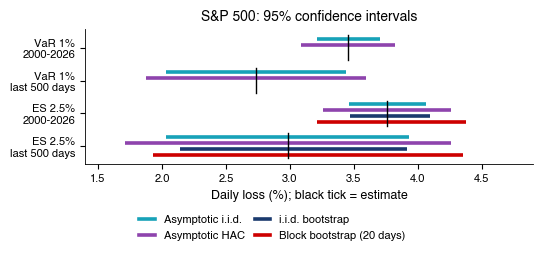

   saved ch7_precision


In [9]:
L = (-rets['sp500']).values
INF = {'se': {'sp500_full': var_es_se(L), 'sp500_w500': var_es_se(L[-500:])}}
B2 = b2_es_boot()
print(INF)
fig_precision(INF, B2)

![ch7_precision](./ch7_precision.png)

Output: `ch7_precision.pdf`